In [21]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

In [2]:
import os
print(os.getcwd())

d:\Sem 5\python\movie-ratings-dashboard


In [3]:
print(os.listdir())        # what's in the current folder
print(os.path.exists("data"))                          # does data/ exist here?
print(os.path.exists("data/title.basics.tsv.gz"))       # is the file actually there?

['data', 'data_loader.py', 'explore.ipynb', 'main.py', '__pycache__']
True
True


In [4]:
os.listdir()

['data', 'data_loader.py', 'explore.ipynb', 'main.py', '__pycache__']

In [5]:
import pandas as pd

basics = pd.read_csv(
    "data/title.basics.tsv.gz",
    sep="\t",
    na_values="\\N",
    low_memory=False
)
print(basics.shape)
print(basics.info())
print(basics.head())

(12810797, 9)
<class 'pandas.DataFrame'>
RangeIndex: 12810797 entries, 0 to 12810796
Data columns (total 9 columns):
 #   Column          Dtype  
---  ------          -----  
 0   tconst          str    
 1   titleType       str    
 2   primaryTitle    str    
 3   originalTitle   str    
 4   isAdult         int64  
 5   startYear       float64
 6   endYear         float64
 7   runtimeMinutes  str    
 8   genres          str    
dtypes: float64(2), int64(1), str(6)
memory usage: 1.7 GB
None
      tconst titleType            primaryTitle           originalTitle  \
0  tt0000001     short              Carmencita              Carmencita   
1  tt0000002     short  Le clown et ses chiens  Le clown et ses chiens   
2  tt0000003     short            Poor Pierrot          Pauvre Pierrot   
3  tt0000004     short             Un bon bock             Un bon bock   
4  tt0000005     short        Blacksmith Scene        Blacksmith Scene   

   isAdult  startYear  endYear runtimeMinutes           

In [6]:
basics['titleType'].value_counts()

titleType
tvEpisode       9906086
short           1158830
movie            757506
video            331495
tvSeries         305668
tvMovie          156274
tvMiniSeries      73125
tvSpecial         60405
videoGame         50335
tvShort           11072
tvPilot               1
Name: count, dtype: int64

In [7]:
movies = basics[basics['titleType'] == 'movie'].copy()
print(movies.shape)

(757506, 9)


In [8]:
ratings = pd.read_csv("data/title.ratings.tsv.gz", sep="\t", na_values="\\N")
print(ratings.shape)
print(ratings.head())

(1713058, 3)
      tconst  averageRating  numVotes
0  tt0000001            5.7      2231
1  tt0000002            5.4       325
2  tt0000003            6.4      2386
3  tt0000004            5.0       202
4  tt0000005            6.2      3097


In [9]:
crew = pd.read_csv("data/title.crew.tsv.gz", sep="\t", na_values="\\N")
print(crew.head())

      tconst  directors    writers
0  tt0000001  nm0005690        NaN
1  tt0000002  nm0721526        NaN
2  tt0000003  nm0721526  nm0721526
3  tt0000004  nm0721526        NaN
4  tt0000005  nm0005690        NaN


In [10]:
print('tconst' in movies.columns, 'tconst' in ratings.columns, 'tconst' in crew.columns)
df = movies.merge(ratings, on="tconst", how="inner")
print(df.shape)

True True True


(348954, 11)


In [11]:
ratings = pd.read_csv("data/title.ratings.tsv.gz", sep="\t", na_values="\\N")
crew = pd.read_csv("data/title.crew.tsv.gz", sep="\t", na_values="\\N")

In [12]:
movies = basics[basics['titleType'] == 'movie'].copy()

In [13]:
df = df.merge(crew[['tconst', 'directors']], on="tconst", how="left")

In [14]:
print(df.isnull().sum())
df = df.dropna(subset=['startYear', 'genres', 'runtimeMinutes'])

tconst                 0
titleType              0
primaryTitle           2
originalTitle          2
isAdult                0
startYear             35
endYear           348954
runtimeMinutes     29937
genres             11464
averageRating          0
numVotes               0
directors           4563
dtype: int64


In [15]:
df['startYear'] = df['startYear'].astype(int)
df['runtimeMinutes'] = df['runtimeMinutes'].astype(int)

In [16]:
df['genres'] = df['genres'].str.split(',')
df_exploded = df.explode('genres')
print(df_exploded['genres'].value_counts())

genres
Drama          147628
Comedy          78639
Documentary     53764
Romance         35203
Action          32409
Crime           28891
Thriller        28116
Horror          25473
Adventure       19682
Mystery         13309
Family          12408
Biography       10743
Fantasy         10092
History          9435
Music            9075
Sci-Fi           7833
Musical          6542
War              6498
Animation        6085
Western          5005
Sport            4301
Adult            4053
Film-Noir         876
News              675
Reality-TV         70
Talk-Show          20
Game-Show           3
Name: count, dtype: int64


In [17]:
df = df[df['numVotes'] >= 1000]
df_exploded = df_exploded[df_exploded['numVotes'] >= 1000]

In [18]:
df['decade'] = (df['startYear'] // 10) * 10
df_exploded['decade'] = (df_exploded['startYear'] // 10) * 10

In [19]:
print(df.shape, df_exploded.shape)
print(df.head())

(48965, 13) (114057, 13)
        tconst titleType                               primaryTitle  \
3    tt0000574     movie                The Story of the Kelly Gang   
102  tt0002130     movie                            Dante's Inferno   
120  tt0002423     movie                                    Passion   
152  tt0002844     movie  Fantômas: In the Shadow of the Guillotine   
164  tt0003014     movie                              Ingeborg Holm   

                              originalTitle  isAdult  startYear  endYear  \
3               The Story of the Kelly Gang        0       1906      NaN   
102                               L'inferno        0       1911      NaN   
120                          Madame DuBarry        0       1919      NaN   
152  Fantômas I: À l'ombre de la guillotine        0       1913      NaN   
164                           Ingeborg Holm        0       1913      NaN   

     runtimeMinutes                          genres  averageRating  numVotes  \
3          

In [20]:
from data_loader import load_movie_data

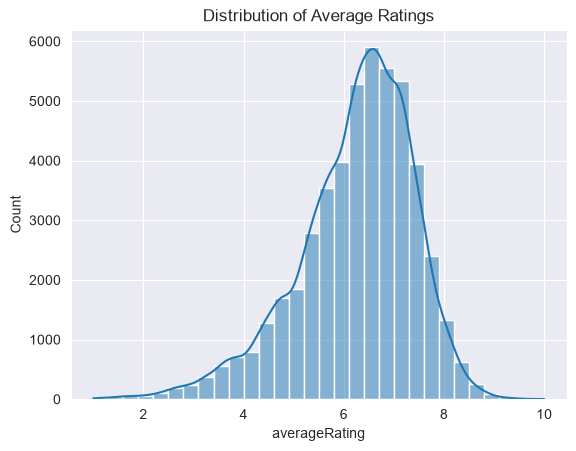

In [22]:
sns.histplot(df['averageRating'], bins=30, kde=True)
plt.title("Distribution of Average Ratings")
plt.show()

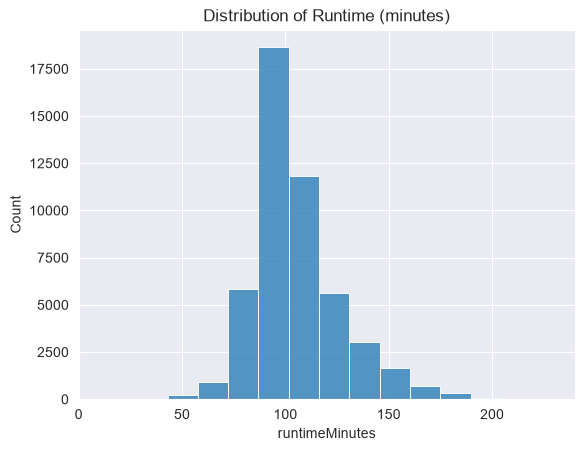

In [23]:
sns.histplot(df['runtimeMinutes'], bins=50)
plt.title("Distribution of Runtime (minutes)")
plt.xlim(0, 240)  # cap the x-axis; outlier runtimes will otherwise squash the chart
plt.show()

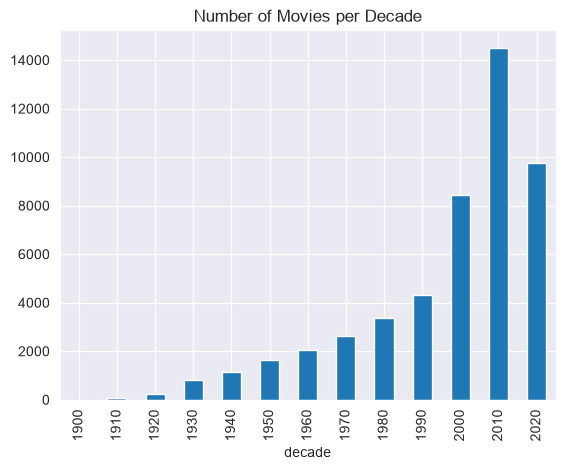

In [24]:
df['decade'].value_counts().sort_index().plot(kind='bar')
plt.title("Number of Movies per Decade")
plt.show()

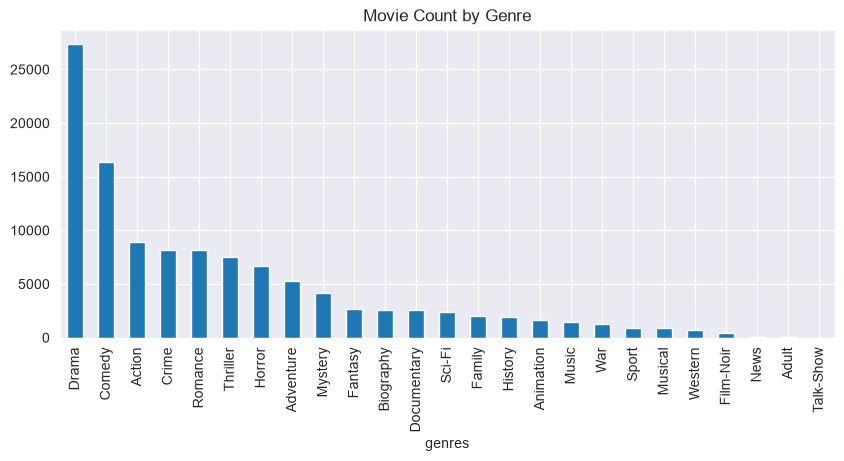

In [25]:
df_exploded['genres'].value_counts().plot(kind='bar', figsize=(10,4))
plt.title("Movie Count by Genre")
plt.show()

In [26]:
df_exploded.groupby('genres')['averageRating'].mean().sort_values(ascending=False)

genres
News           7.565517
Documentary    7.187364
Biography      6.902309
Film-Noir      6.849028
History        6.823129
Talk-Show      6.800000
War            6.775285
Music          6.702755
Animation      6.631592
Musical        6.581988
Sport          6.534853
Drama          6.489698
Western        6.393233
Romance        6.387221
Crime          6.299474
Family         6.225231
Comedy         6.153166
Adventure      6.103107
Mystery        5.977082
Fantasy        5.943228
Action         5.927993
Thriller       5.821969
Adult          5.694444
Sci-Fi         5.437688
Horror         5.251302
Name: averageRating, dtype: float64

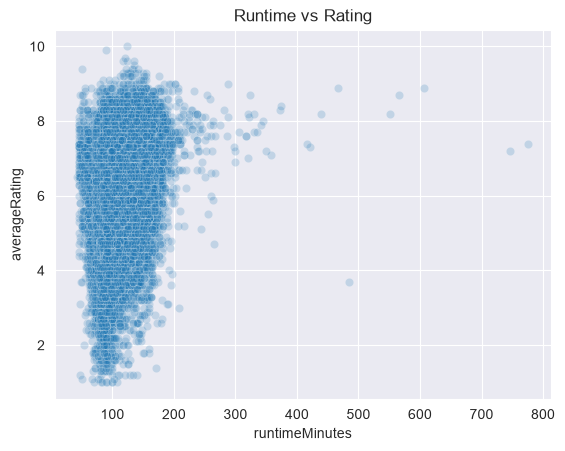

In [27]:
sns.scatterplot(data=df, x='runtimeMinutes', y='averageRating', alpha=0.2)
plt.title("Runtime vs Rating")
plt.show()

In [28]:
director_stats = df.groupby('directors')['averageRating'].agg(['mean', 'std', 'count'])
director_stats = director_stats[director_stats['count'] >= 5]
director_stats.sort_values('std').head(10)   # most consistent
director_stats.sort_values('std', ascending=False).head(10)  # most polarizing

,mean,std,count
directors,,,
nm2134474,5.820000,2.517340,5
nm0007144,5.983333,2.226582,6
nm1349318,4.180000,2.183346,5
nm0754184,6.520000,2.147557,5
nm2949515,6.000000,2.068816,5
nm0160840,5.454545,2.060274,11
nm0149134,5.237500,2.052829,8
nm1989536,6.233333,2.037318,6
nm1150959,5.550000,2.020643,6


In [29]:
genre_avg_rating = df_exploded.groupby('genres')['averageRating'].mean().sort_values(ascending=False)
print(genre_avg_rating)

genres
News           7.565517
Documentary    7.187364
Biography      6.902309
Film-Noir      6.849028
History        6.823129
Talk-Show      6.800000
War            6.775285
Music          6.702755
Animation      6.631592
Musical        6.581988
Sport          6.534853
Drama          6.489698
Western        6.393233
Romance        6.387221
Crime          6.299474
Family         6.225231
Comedy         6.153166
Adventure      6.103107
Mystery        5.977082
Fantasy        5.943228
Action         5.927993
Thriller       5.821969
Adult          5.694444
Sci-Fi         5.437688
Horror         5.251302
Name: averageRating, dtype: float64


In [30]:
decade_avg_rating = df.groupby('decade')['averageRating'].mean().sort_index()
print(decade_avg_rating)

decade
1900    6.000000
1910    6.673684
1920    7.026033
1930    6.791646
1940    6.802892
1950    6.652862
1960    6.609615
1970    6.462915
1980    6.268357
1990    6.332987
2000    6.202365
2010    6.070411
2020    6.085981
Name: averageRating, dtype: float64


In [31]:
genre_decade_matrix = df_exploded.pivot_table(
    index='genres',
    columns='decade',
    values='averageRating',
    aggfunc='mean'
)
print(genre_decade_matrix)

decade       1900      1910      1920      1930      1940      1950      1960  \
genres                                                                          
Action        6.0  6.300000  7.244444  6.587805  6.642105  6.411628  6.377215   
Adult         NaN       NaN       NaN       NaN       NaN       NaN       NaN   
Adventure     6.0  6.600000  6.987879  6.807447  6.639844  6.345815  6.352679   
Animation     NaN       NaN  7.800000  7.266667  6.793333  7.230000  7.005263   
Biography     6.0  6.750000  7.166667  6.755172  6.852174  6.794048  7.072131   
Comedy        NaN  6.727273  6.998630  6.873720  6.787147  6.799413  6.594286   
Crime         NaN  6.890000  6.800000  6.788710  6.783513  6.733846  6.626510   
Documentary   NaN       NaN  7.537500  7.142857  6.811111  7.437500  7.140741   
Drama         NaN  6.667442  7.023030  6.786789  6.894423  6.866092  6.889321   
Family        NaN  6.533333  7.253333  6.890000  6.900000  6.560241  6.542157   
Fantasy       NaN  6.628571 

In [33]:
runtime_rating_corr = df['runtimeMinutes'].corr(df['averageRating'])
print(f"Correlation: {runtime_rating_corr:.3f}")
corr_by_genre = df_exploded.groupby('genres').apply(
    lambda g: g['runtimeMinutes'].corr(g['averageRating'])
).sort_values(ascending=False)
print(corr_by_genre)


Correlation: 0.256
genres
Film-Noir      0.458649
Thriller       0.408645
Sci-Fi         0.386583
Mystery        0.341225
Western        0.301701
Horror         0.290598
Action         0.290167
Crime          0.271523
Fantasy        0.265565
Adventure      0.263408
Family         0.257175
Drama          0.234905
Sport          0.234404
Musical        0.227098
Animation      0.211827
News           0.201639
Romance        0.199983
Music          0.196513
Comedy         0.191362
War            0.181527
History        0.157646
Biography      0.151610
Documentary    0.141736
Adult         -0.226442
Talk-Show           NaN
dtype: float64


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3028: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:2901: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:2901: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [34]:
MIN_FILMS = 5
director_stats = df.groupby('directors')['averageRating'].agg(['mean', 'std', 'count'])
director_stats = director_stats[director_stats['count'] >= MIN_FILMS]

most_consistent = director_stats.sort_values('std').head(10)
most_polarizing = director_stats.sort_values('std', ascending=False).head(10)

In [35]:
top_movies = df[df['numVotes'] >= 5000].sort_values('averageRating', ascending=False)
top_movies = top_movies[['primaryTitle', 'startYear', 'averageRating', 'numVotes', 'runtimeMinutes']]
print(top_movies.head(20))

                                          primaryTitle  startYear  \
278044                                   Mission C1000       2026   
62386                         The Shawshank Redemption       1994   
37435                                    The Godfather       1972   
104132             Ramayana: The Legend of Prince Rama       1993   
283455                                        Mandaadi       2026   
102228                                 The Chaos Class       1975   
140284                                 The Dark Knight       2008   
39367                            The Godfather Part II       1974   
101488                                       Mayabazar       1957   
60809                                 Schindler's List       1993   
299094  BLEACH: Thousand-Year Blood War - The Calamity       2026   
299802                                    Tom & Cherry       2026   
196021                                     Unpaarvayil       2025   
24267                             

In [37]:
import data_loader
print(dir(data_loader))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'load_movie_data', 'pd']


In [38]:
import importlib
import data_loader
importlib.reload(data_loader)
from data_loader import genre_avg_rating, decade_avg_rating, genre_decade_matrix, director_consistency, top_movies

In [39]:
from data_loader import genre_avg_rating, decade_avg_rating, genre_decade_matrix, director_consistency, top_movies
print(genre_avg_rating(df_exploded).head())

genres
News           7.565517
Documentary    7.187364
Biography      6.902309
Film-Noir      6.849028
History        6.823129
Name: averageRating, dtype: float64


In [1]:
# run once in your notebook or a throwaway script
from data_loader import load_movie_data

df, df_exploded = load_movie_data(min_votes=1000)
df.to_csv("data/movies_cleaned.csv", index=False)
df_exploded.to_csv("data/movies_exploded.csv", index=False)